# Homework 3 : Classification

<div class="alert alert-block alert-info">
<b>NOTE:</b> 
This homework uses the pinned 2026 lead-scoring release in the course repository.
The plan and report are available in <b><code>cohorts/2026/data/</code></b>.
</div>

## Dataset

In this homework, we will use the 2026 lead-scoring dataset. Download it from [here](https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv).

Or you can do it with `wget`:

In [1]:
data = 'https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv'
!wget -N $data -P ../data/

--2026-10-12 16:37:12--  https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 2606:50c0:8002::154, 2606:50c0:8000::154, 2606:50c0:8001::154, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|2606:50c0:8002::154|:443... 

connected.


HTTP request sent, awaiting response... 

200 OK
Length: 278746 (272K) [text/plain]


Saving to: ‘../data/course_lead_scoring_2026.csv’


          course_le   0%[                    ]       0  --.-KB/s               


course_lead_scoring 100%[===================>] 272.21K  --.-KB/s    in 0.1s    

Last-modified header missing -- time-stamps turned off.
2026-10-12 16:37:13 (1.98 MB/s) - ‘../data/course_lead_scoring_2026.csv’ saved [278746/278746]



In this dataset our desired target for classification task will be `converted` variable - has the client signed up to the platform or not.

## Data preparation

* Check if the missing values are presented in the features.
* If there are missing values:
    * For categorical features, replace them with 'NA'
    * For numerical features, replace with with 0.0

In [2]:
import pandas as pd
import numpy as np

In [3]:
df = pd.read_csv('../data/course_lead_scoring_2026.csv')

In [4]:
df.head()

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NaN,NaN,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1


In [5]:
df.dtypes

lead_source                     str
industry                        str
employment_status               str
location                        str
annual_income               float64
number_of_courses_viewed      int64
interaction_count             int64
lead_score                  float64
converted                     int64
dtype: object

In [6]:
df.isnull().sum()

lead_source                 148
industry                    240
employment_status           194
location                    208
annual_income               369
number_of_courses_viewed      0
interaction_count             0
lead_score                   35
converted                     0
dtype: int64

In [7]:
# Replace values with 'NA' or 0.0
categorical = df.select_dtypes(exclude='number').columns
numerical = df.select_dtypes(include='number').columns

df[categorical] = df[categorical].fillna('NA')
df[numerical] = df[numerical].fillna(0.0)

In [8]:
numerical , categorical

(Index(['annual_income', 'number_of_courses_viewed', 'interaction_count',
        'lead_score', 'converted'],
       dtype='str'),
 Index(['lead_source', 'industry', 'employment_status', 'location'], dtype='str'))

In [9]:
df.head()

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NA,0.0,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1


In [10]:
df.isnull().sum()

lead_source                 0
industry                    0
employment_status           0
location                    0
annual_income               0
number_of_courses_viewed    0
interaction_count           0
lead_score                  0
converted                   0
dtype: int64

## Question 1

What is the most frequent observation (mode) for the column `industry`?

In [11]:
df.industry.mode()

0    technology
Name: industry, dtype: str

## Question 2

Create the [correlation matrix](https://www.google.com/search?q=correlation+matrix) for the numerical features of your dataset.
In a correlation matrix, you compute the correlation coefficient between every pair of features.

What are the two features that have the biggest correlation?

- `interaction_count` and `lead_score`
- `number_of_courses_viewed` and `lead_score`
- `number_of_courses_viewed` and `interaction_count`
- `annual_income` and `interaction_count`

Only consider the pairs above when answering this question.

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns

In [13]:
corr_matrix = df[numerical].corr()
corr_matrix

,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
annual_income,1.000000,0.161300,0.122842,0.229496,0.189652
number_of_courses_viewed,0.161300,1.000000,0.721609,0.757204,0.395038
interaction_count,0.122842,0.721609,1.000000,0.915746,0.448624
lead_score,0.229496,0.757204,0.915746,1.000000,0.483246
converted,0.189652,0.395038,0.448624,0.483246,1.000000


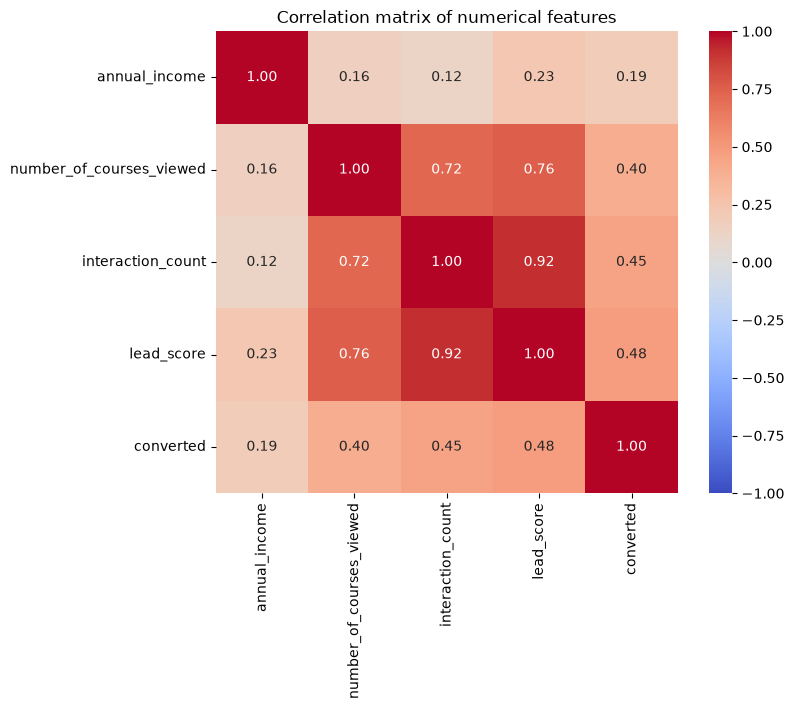

In [14]:
plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, square=True)
plt.title('Correlation matrix of numerical features')
plt.show()

In [15]:
pairs = [
    ('interaction_count', 'lead_score'),
    ('number_of_courses_viewed', 'lead_score'),
    ('number_of_courses_viewed', 'interaction_count'),
    ('annual_income', 'interaction_count'),
]

for a, b in pairs:
    print(f'{a} - {b}: {corr_matrix.loc[a, b]:.4f}')

interaction_count - lead_score: 0.9157
number_of_courses_viewed - lead_score: 0.7572
number_of_courses_viewed - interaction_count: 0.7216
annual_income - interaction_count: 0.1228


**Answer:** `interaction_count` and `lead_score` have the biggest correlation (≈ 0.92).

## Split the data

- Split the data with these exact calls:

In [16]:
from sklearn.model_selection import train_test_split

In [17]:
# Categorical features only (the non-numeric columns defined during data preparation)
categorical

Index(['lead_source', 'industry', 'employment_status', 'location'], dtype='str')

In [18]:
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=42)
df_train, df_val = train_test_split(
    df_full_train, test_size=0.25, random_state=42
)

df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

y_train = df_train.converted.values
y_val = df_val.converted.values
y_test = df_test.converted.values

del df_train['converted']
del df_val['converted']
del df_test['converted']

- Make sure that the target value `converted` is not in your dataframe.


In [19]:
df_train.shape, y_train.shape

((3000, 8), (3000,))

In [20]:
df_train.head()

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score
0,paid_ads,finance,employed,asia,65980.0,2,3,0.37
1,events,finance,employed,south_america,71662.0,0,0,0.09
2,referral,NA,employed,asia,40220.0,2,5,0.55
3,organic_search,finance,employed,north_america,88352.0,2,2,0.45
4,events,technology,employed,north_america,89316.0,1,5,0.00


## Question 3

- Calculate the mutual information score between `converted` and other categorical variables in the dataset. Use the training set only.
- Round the scores to 2 decimals using `round(score, 2)`.

Which of these variables has the biggest mutual information score?


In [21]:
from sklearn.metrics import mutual_info_score

In [22]:
def mutual_info_converted_score(series):
    return mutual_info_score(series, y_train)

In [23]:
mi = df_train[categorical].apply(mutual_info_converted_score)
mi.round(2).sort_values(ascending=False)

lead_source          0.03
employment_status    0.02
industry             0.00
location             0.00
dtype: float64

**Answer:** `lead_source` has the biggest mutual information score with `converted` (0.03).

## Question 4

- Now let's train a logistic regression.
- Remember that we have several categorical variables in the dataset. Include them using one-hot encoding.
- Fit the model on the training dataset.
  - To make sure the results are reproducible across different versions of Scikit-Learn, fit the model with these parameters:
  - `model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000, random_state=42)`
- Calculate the accuracy on the validation dataset and round it to 2 decimal digits.

What accuracy did you get?


In [24]:
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import OneHotEncoder

In [25]:
from sklearn.linear_model import LogisticRegression

In [26]:
numerical.tolist()

['annual_income',
 'number_of_courses_viewed',
 'interaction_count',
 'lead_score',
 'converted']

In [27]:
numerical = numerical.drop('converted')

Now let's process categorical features using `OneHotEncoding`.
We'll write the results to `X_train_cat`:

In [28]:
ohe = OneHotEncoder(sparse_output=False, handle_unknown='ignore')

Now we need to combine two matrices into one - `X_train`:

In [29]:
X_train_num = df_train[numerical].values      
X_train_cat = ohe.fit_transform(df_train[categorical].values)
X_train = np.column_stack([X_train_num, X_train_cat])
X_val_num = df_val[numerical].values          
X_val_cat = ohe.transform(df_val[categorical].values)
X_val = np.column_stack([X_val_num, X_val_cat])

In [30]:
ohe.get_feature_names_out()

array(['x0_NA', 'x0_events', 'x0_organic_search', 'x0_paid_ads',
       'x0_referral', 'x0_social_media', 'x1_NA', 'x1_education',
       'x1_finance', 'x1_healthcare', 'x1_manufacturing', 'x1_retail',
       'x1_technology', 'x2_NA', 'x2_employed', 'x2_self_employed',
       'x2_student', 'x2_unemployed', 'x3_NA', 'x3_africa', 'x3_asia',
       'x3_europe', 'x3_north_america', 'x3_south_america'], dtype=object)

In [31]:
model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000, random_state=42)
model.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",42
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`multiclass` problems (`n_classes >= 3`), all solvers except 'liblinear' minimize the full multinomial loss, 'liblinear' will raise an error.- 'newton-cholesky' is a good choice for `n_samples` >> `n_features * n_classes`, especially with one-hot encoded categorical features with rare categories. Be aware that the memory usage of this solver has a quadratic dependency on `n_features * n_classes` because it explicitly computes the full Hessian matrix.- For small datasets, 'liblinear' is a good choice, whereas 'sag' and 'saga' are faster for large ones;- 'liblinear' can only handle binary classification by default. To apply a one-versus-rest scheme for the multiclass setting one can wrap it with the :class:`~sklearn.multiclass.OneVsRestClassifier`... warning:: The choice of the algorithm depends on the penalty chosen (`l1_ratio=0` for L2-penalty, `l1_ratio=1` for L1-penalty and `0 < l1_ratio < 1` for Elastic-Net) and on (multinomial) multiclass support: ================= ======================== ====================== solver l1_ratio multinomial multiclass ================= ======================== ====================== 'lbfgs' l1_ratio=0 yes 'liblinear' l1_ratio=1 or l1_ratio=0 no 'newton-cg' l1_ratio=0 yes 'newton-cholesky' l1_ratio=0 yes 'sag' l1_ratio=0 yes 'saga' 0<=l1_ratio<=1 yes ================= ======================== ======================.. note:: 'sag' and 'saga' fast convergence is only guaranteed on features with approximately the same scale. You can preprocess the data with a scaler from :mod:`sklearn.preprocessing`... seealso:: Refer to the :ref:`User Guide <Logistic_regression>` for more information regarding :class:`LogisticRegression` and more specifically the :ref:`Table <logistic_regression_solvers>` summarizing solver/penalty supports... versionadded:: 0.17 Stochastic Average Gradient (SAG) descent solver. Multinomial support in version 0.18... versionadded:: 0.19 SAGA solver... versionchanged:: 0.22 The default solver changed from 'liblinear' to 'lbfgs' in 0.22... versionadded:: 1.2 newton-cholesky solver. Multinomial support in version 1.6.",'liblinear'
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l

We can check it's accuracy:

In [32]:
y_pred = model.predict_proba(X_val)[:, 1]   # probability of converted = 1
converted_decision = (y_pred >= 0.5)        # True/False using a 0.5 threshold

In [33]:
accuracy = (converted_decision == y_val).mean()
round(accuracy, 2)

np.float64(0.64)

## Question 5

- Let's find the least useful feature using the _feature elimination_ technique.
- Train a model using the same features and parameters as in Q4 (without rounding).
- Now exclude each feature from this set and train a model without it. Record the accuracy for each model.
- For each feature, calculate the difference between the original accuracy and the accuracy without the feature.

Which of following feature has the smallest difference?

Helper that one-hot encodes the categorical columns, keeps the numerical ones as they are (same as Q4), trains the model and returns the validation accuracy for any list of features:

In [34]:
def train_and_evaluate(features):
    cat = [c for c in features if c in categorical]
    num = [n for n in features if n in numerical]

    ohe = OneHotEncoder(sparse_output=False, handle_unknown='ignore')

    X_train = np.column_stack([df_train[num].values, ohe.fit_transform(df_train[cat].values)])
    X_val = np.column_stack([df_val[num].values, ohe.transform(df_val[cat].values)])

    model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000, random_state=42)
    model.fit(X_train, y_train)

    return (model.predict(X_val) == y_val).mean()

In [35]:
all_features = list(categorical) + list(numerical)

base_accuracy = train_and_evaluate(all_features)
base_accuracy

np.float64(0.645)

In [36]:
results = []

for feature in all_features:
    features = [f for f in all_features if f != feature]
    acc = train_and_evaluate(features)
    results.append((feature, acc, base_accuracy - acc))

df_elimination = pd.DataFrame(results, columns=['removed_feature', 'accuracy', 'difference'])
df_elimination['abs_difference'] = df_elimination.difference.abs()
df_elimination.sort_values('abs_difference')

,removed_feature,accuracy,difference,abs_difference
1,industry,0.645,0.000,0.000
2,employment_status,0.645,0.000,0.000
3,location,0.645,0.000,0.000
7,lead_score,0.644,0.001,0.001
5,number_of_courses_viewed,0.643,0.002,0.002
0,lead_source,0.642,0.003,0.003
6,interaction_count,0.601,0.044,0.044
4,annual_income,0.724,-0.079,0.079


**Answer:** among the options (`lead_source`, `number_of_courses_viewed`, `interaction_count`), `number_of_courses_viewed` has the smallest difference (0.002).

## Question 6

- Now let's train a regularized logistic regression.
- Let's try the following values of the parameter `C`: `[0.000001, 0.00001, 0.0001, 0.001]`.
- Train models using all the features as in Q4.
- Calculate the accuracy on the validation dataset and round it to 3 decimal digits.

Which of these `C` leads to the best accuracy on the validation set?

> **Note**: If there are multiple options, select the smallest `C`.

<details>
<summary>Note from library</summary>

<code>
C : float, default=1.0
    Inverse of regularization strength; must be a positive float.
    Like in support vector machines, smaller values specify stronger
    regularization. `C=np.inf` results in unpenalized logistic regression.
    For a visual example on the effect of tuning the `C` parameter
    with an L1 penalty, see:
    :ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.
</code>

</details>

In [60]:
for C in [0.000001, 0.00001, 0.0001, 0.001]:
    model = LogisticRegression(solver='liblinear', C=C, max_iter=1000, random_state=42)
    model.fit(X_train, y_train)

    accuracy = (model.predict(X_val) == y_val).mean()
    print(f'C={C:>6}: {round(accuracy, 3)}')

C= 1e-06: 0.598
C= 1e-05: 0.598
C=0.0001: 0.613
C= 0.001: 0.645


**Answer:** `C = 0.001` gives the best validation accuracy (0.645). Stronger regularization (smaller `C`) lowers the accuracy: 0.613 for `C = 0.0001` and 0.598 for `C = 0.00001` and `C = 0.000001`.